# 16 — PVOD data preparation and forecasting protocol

## Purpose

The preceding PVOD exploration identified ten PV sites, a 15-minute observation cadence, genuine timestamp gaps, and one documented timestamp correction in station00. This notebook reconstructs the **same preparation and forecasting protocol** used in the completed PVOD evaluation, with reproducible checks of the forecasting populations and F0–F4 feature structure.

The target is future PV **power**, expressed in units of nominal plant capacity (p.u.). We retain eligible day and night observations in training and report separate target-valid-time daylight populations to support the solar forecasting analysis.

## 1. Load the PVOD protocol and site registry

Every station has a separate nominal capacity and geographical location. We interpret the raw station timestamps as UTC, preserve the 15-minute resolution, and use the fixed correction for station00. All feature and split definitions come from the existing `src.pvod` and astronomical/calendar methods.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src" / "pvod.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook inside the SOLETE research repository.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.pvod import (
    PVOD_CADENCE, PVOD_EXPECTED_DIMS, PVOD_METEOROLOGICAL_COLUMNS,
    PVOD_TIMESTAMP_CORRECTIONS, build_pvod_site_registry,
    build_pvod_split_boundaries, build_pvod_f0,
    build_pvod_solar_features, build_pvod_sample_indices,
    materialize_pvod_design, clean_pvod_station,
)
from src.preprocessing import build_gregorian_features
from src.astronomy_features import (
    apparent_tropical_ecliptic_longitudes, load_jpl_ephemeris,
    moon_ecliptic_latitude_and_distance, moon_illumination_fraction,
    moon_sun_phase_angle_deg, skyfield_times_from_utc,
)
from src.vedic_calendar import (
    build_panchang_f4_raw, lahiri_ayanamsha_for_utc_times,
    sidereal_longitude_from_tropical,
    yoga_angle_from_tropical_longitudes,
)
from src.feature_families import encode_panchang_fixed_vocabulary

PVOD_ROOT = PROJECT_ROOT / "external_data" / "PVOD"
EPHEMERIS_FILE = PROJECT_ROOT / "ephemeris" / "de440s.bsp"
STATIONS = tuple(f"station{i:02d}" for i in range(10))
HORIZONS = (15, 30, 60)
assert PVOD_CADENCE == pd.Timedelta(minutes=15)
assert PVOD_EXPECTED_DIMS == {"F0": 71, "F1": 86, "F2": 91, "F3": 100, "F4": 197}
assert set(PVOD_TIMESTAMP_CORRECTIONS) == {"station00"}
for path in [PVOD_ROOT / "metadata.csv", EPHEMERIS_FILE]:
    if not path.is_file():
        raise FileNotFoundError(path)
for station in STATIONS:
    if not (PVOD_ROOT / f"{station}.csv").is_file():
        raise FileNotFoundError(station)

registry = build_pvod_site_registry(pd.read_csv(PVOD_ROOT / "metadata.csv"))
assert len(registry) == 10 and set(registry["station"]) == set(STATIONS)
site_lookup = registry.set_index("station").loc[list(STATIONS)]
print("PVOD protocol: 10 stations, 15-minute resolution, 15/30/60-minute horizons")
display(registry[["station", "capacity_MW", "latitude_deg", "longitude_deg"]])

PVOD protocol: 10 stations, 15-minute resolution, 15/30/60-minute horizons


,station,capacity_MW,latitude_deg,longitude_deg
0,station00,6.6,38.047780,114.951390
1,station01,20.0,38.183060,117.457220
2,station02,17.0,38.057280,114.198870
3,station03,20.0,38.109560,114.114940
4,station04,20.0,39.515500,114.867670
5,station05,35.0,38.235500,114.123600
6,station06,15.0,36.898910,114.548410
7,station07,20.0,36.644030,113.641870
8,station08,20.0,36.707610,113.899990
9,station09,20.0,38.731417,115.059855


## 2. Clean the observation timelines and establish chronological boundaries

The cleaning function retains the source's observed meteorological variables and PV measurements. Its documented timestamp correction applies to the single guarded station00 row; the other stations retain their original timestamp values. Gaps remain missing rather than being interpolated.

Each station is divided by **elapsed time span** into approximately 65% training, 15% validation and 20% retrospective evaluation. Boundaries are rounded up to the next 15-minute timestamp. Later sample assignment is based on **target-valid time**.

In [2]:
clean_stations = {}
for station in STATIONS:
    raw = pd.read_csv(PVOD_ROOT / f"{station}.csv")
    assert {"date_time", "power", *PVOD_METEOROLOGICAL_COLUMNS}.issubset(raw.columns)
    clean = clean_pvod_station(
        raw, station_id=station,
        capacity_kw=float(site_lookup.loc[station, "capacity_kW"]),
    )
    times = pd.DatetimeIndex(clean["timestamp_utc"])
    assert len(clean) == len(raw) and times.is_monotonic_increasing and times.is_unique
    assert str(times.tz) == "UTC"
    assert np.isfinite(clean["power_pu"].to_numpy(dtype=float)).all()
    assert np.allclose(clean["power_MW"],
                       clean["power_pu"] * float(site_lookup.loc[station, "capacity_MW"]))
    clean_stations[station] = clean

boundaries = build_pvod_split_boundaries(clean_stations)
assert len(boundaries) == 10 and set(boundaries["station"]) == set(STATIONS)
assert (boundaries["station_start_utc"] < boundaries["validation_start_utc"]).all()
assert (boundaries["validation_start_utc"] < boundaries["test_start_utc"]).all()
assert (boundaries["test_start_utc"] < boundaries["station_stop_exclusive_utc"]).all()
print("Station-specific chronological split boundaries:")
display(boundaries)
print("Total corrected PVOD observations:", sum(len(x) for x in clean_stations.values()))

Station-specific chronological split boundaries:


,station,station_start_utc,validation_start_utc,test_start_utc,station_stop_exclusive_utc
0,station00,2018-08-15 16:00:00+00:00,2019-02-27 23:15:00+00:00,2019-04-14 06:30:00+00:00,2019-06-13 16:00:00+00:00
1,station01,2018-06-30 16:00:00+00:00,2019-02-11 21:00:00+00:00,2019-04-05 01:45:00+00:00,2019-06-13 16:00:00+00:00
2,station02,2018-07-22 16:00:00+00:00,2019-02-17 15:00:00+00:00,2019-04-07 01:45:00+00:00,2019-06-10 16:00:00+00:00
3,station03,2019-01-11 16:00:00+00:00,2019-04-21 03:00:00+00:00,2019-05-14 01:45:00+00:00,2019-06-13 16:00:00+00:00
4,station04,2018-06-30 16:00:00+00:00,2019-02-11 21:00:00+00:00,2019-04-05 01:45:00+00:00,2019-06-13 16:00:00+00:00
5,station05,2019-03-04 16:00:00+00:00,2019-05-09 07:45:00+00:00,2019-05-24 11:15:00+00:00,2019-06-13 16:00:00+00:00
6,station06,2018-07-13 16:00:00+00:00,2019-02-16 10:00:00+00:00,2019-04-07 16:00:00+00:00,2019-06-13 16:00:00+00:00
7,station07,2018-06-30 16:00:00+00:00,2019-02-11 21:00:00+00:00,2019-04-05 01:45:00+00:00,2019-06-13 16:00:00+00:00
8,station08,2018-06-30 16:00:00+00:00,2019-02-11 21:00:00+00:00,2019-04-05 01:45:00+00:00,2019-06-13 16:00:00+00:00
9,station09,2018-09-25 16:00:00+00:00,2019-03-14 07:45:00+00:00,2019-04-22 11:15:00+00:00,2019-06-13 16:00:00+00:00


Total corrected PVOD observations: 271968


## 3. Build issue-time F0 and horizon-specific eligible samples

F0 uses **14 dynamic observational channels at five issue-time lags** (at −60, −45, −30, −15 and 0 minutes), plus previous-day PV power at the same clock time: \(14\times5+1=71\) predictors.

For every eligible issue time, the complete observed history must exist and all intermediate future 15-minute timestamps through the forecast-valid time must exist. These checks avoid bridging genuine time gaps. Targets and the geometric daylight flag are read at valid time; observed predictors remain at issue time or earlier.

In [3]:
EXPECTED_COUNTS = {
    # Per horizon: (availability-safe development refit rows, retrospective test rows).
    "station00": {15: (22900, 5798), 30: (22898, 5798), 60: (22894, 5798)},
    "station01": {15: (26626, 6681), 30: (26625, 6681), 60: (26623, 6681)},
    "station02": {15: (24321, 5719), 30: (24319, 5717), 60: (24315, 5713)},
    "station03": {15: (11650, 2937), 30: (11649, 2937), 60: (11647, 2937)},
    "station04": {15: (26626, 6681), 30: (26625, 6681), 60: (26623, 6681)},
    "station05": {15: (7656, 1939), 30: (7655, 1939), 60: (7653, 1939)},
    "station06": {15: (24279, 6239), 30: (24274, 6238), 60: (24264, 6236)},
    "station07": {15: (26049, 6681), 30: (26047, 6681), 60: (26043, 6681)},
    "station08": {15: (26241, 6681), 30: (26239, 6681), 60: (26235, 6681)},
    "station09": {15: (19270, 4529), 30: (19267, 4527), 60: (19261, 4523)},
}
assert set(EXPECTED_COUNTS) == set(STATIONS)

F0_BY_STATION = {}
SOLAR_BY_STATION = {}
SAMPLES_BY_STATION = {}
population_rows = []
for station in STATIONS:
    clean = clean_stations[station]
    times = pd.DatetimeIndex(clean["timestamp_utc"])
    f0 = build_pvod_f0(clean)
    solar = build_pvod_solar_features(
        times,
        latitude_deg=float(site_lookup.loc[station, "latitude_deg"]),
        longitude_deg=float(site_lookup.loc[station, "longitude_deg"]),
    )
    boundary = boundaries.set_index("station").loc[station]
    samples = build_pvod_sample_indices(clean, f0, boundary, solar)
    assert f0.shape == (len(clean), 71)
    assert solar.shape == (len(clean), 5)
    assert f0.index.equals(times) and solar.index.equals(times)
    assert set(samples) == set(HORIZONS)
    F0_BY_STATION[station] = f0
    SOLAR_BY_STATION[station] = solar
    SAMPLES_BY_STATION[station] = samples

    first_test_issues = {
        h: samples[h].loc[samples[h]["split"].eq("test"), "issue_time_utc"].iloc[0]
        for h in HORIZONS
    }
    # The cutoff is shared across horizons: a development label must be
    # known before the earliest retrospective issue time at this site.
    cutoff = min(first_test_issues.values())
    observed_pu = clean.set_index("timestamp_utc")["power_pu"]
    for horizon in HORIZONS:
        rows = samples[horizon]
        assert rows["split"].isin(("train", "validation", "test")).all()
        assert (rows["target_time_utc"] - rows["issue_time_utc"]
                == pd.Timedelta(minutes=horizon)).all()
        refit_mask = (rows["split"].isin(("train", "validation"))
                      & rows["target_time_utc"].lt(cutoff))
        test_mask = rows["split"].eq("test")
        assert refit_mask.any() and test_mask.any()
        assert not (refit_mask & test_mask).any()
        assert rows.loc[refit_mask, "target_time_utc"].max() < rows.loc[test_mask, "issue_time_utc"].min()
        count_pair = (int(refit_mask.sum()), int(test_mask.sum()))
        assert count_pair == EXPECTED_COUNTS[station][horizon], (station, horizon, count_pair)

        test_samples = rows.loc[test_mask]
        assert observed_pu.reindex(pd.DatetimeIndex(test_samples["issue_time_utc"])).notna().all()
        assert observed_pu.reindex(pd.DatetimeIndex(test_samples["target_time_utc"])
                                    - pd.Timedelta(hours=24)).notna().all()
        population_rows.append({
            "station": station, "horizon_min": horizon,
            "sample_train_rows": int(rows["split"].eq("train").sum()),
            "sample_validation_rows": int(rows["split"].eq("validation").sum()),
            "sample_test_rows": count_pair[1],
            "refit_rows_label_safe": count_pair[0],
            "test_daylight_rows": int(test_samples["target_solar_daylight"].sum()),
            "test_night_rows": int((1 - test_samples["target_solar_daylight"]).sum()),
            "first_test_issue_UTC": first_test_issues[horizon],
            "training_label_cutoff_UTC": cutoff,
        })
    print(f"{station}: gap-safe horizons and training-label cutoff verified")

populations = pd.DataFrame(population_rows)
assert len(populations) == 30
assert populations.groupby("horizon_min")["sample_test_rows"].sum().to_dict() == {
    15: 53885, 30: 53880, 60: 53870,
}
assert (populations["test_daylight_rows"] + populations["test_night_rows"]
        == populations["sample_test_rows"]).all()
print("Matched station-by-horizon forecasting populations:")
display(populations)
print("Total retrospective samples across all horizons:",
      int(populations["sample_test_rows"].sum()))

station00: gap-safe horizons and training-label cutoff verified
station01: gap-safe horizons and training-label cutoff verified
station02: gap-safe horizons and training-label cutoff verified
station03: gap-safe horizons and training-label cutoff verified
station04: gap-safe horizons and training-label cutoff verified
station05: gap-safe horizons and training-label cutoff verified
station06: gap-safe horizons and training-label cutoff verified
station07: gap-safe horizons and training-label cutoff verified
station08: gap-safe horizons and training-label cutoff verified
station09: gap-safe horizons and training-label cutoff verified
Matched station-by-horizon forecasting populations:


,station,horizon_min,sample_train_rows,sample_validation_rows,sample_test_rows,refit_rows_label_safe,test_daylight_rows,test_night_rows,first_test_issue_UTC,training_label_cutoff_UTC
0,station00,15,18555,4349,5798,22900,3366,2432,2019-04-14 06:15:00+00:00,2019-04-14 05:30:00+00:00
1,station00,30,18553,4349,5798,22898,3366,2432,2019-04-14 06:00:00+00:00,2019-04-14 05:30:00+00:00
2,station00,60,18549,4349,5798,22894,3366,2432,2019-04-14 05:30:00+00:00,2019-04-14 05:30:00+00:00
3,station01,15,21619,5011,6681,26626,3850,2831,2019-04-05 01:30:00+00:00,2019-04-05 00:45:00+00:00
4,station01,30,21618,5011,6681,26625,3850,2831,2019-04-05 01:15:00+00:00,2019-04-05 00:45:00+00:00
5,station01,60,21616,5011,6681,26623,3850,2831,2019-04-05 00:45:00+00:00,2019-04-05 00:45:00+00:00
6,station02,15,19674,4651,5719,24321,3296,2423,2019-04-07 01:30:00+00:00,2019-04-07 00:45:00+00:00
7,station02,30,19672,4651,5717,24319,3296,2421,2019-04-07 01:15:00+00:00,2019-04-07 00:45:00+00:00
8,station02,60,19668,4651,5713,24315,3296,2417,2019-04-07 00:45:00+00:00,2019-04-07 00:45:00+00:00
9,station03,15,9451,2203,2937,11650,1764,1173,2019-05-14 01:30:00+00:00,2019-05-14 00:45:00+00:00


Total retrospective samples across all horizons: 161635


## 4. Verify exact-valid-time F1–F4 feature construction

The PVOD nested predictor families have dimensions **71, 86, 91, 100 and 197**. The deterministic blocks are Gregorian calendar (15), site-specific solar geometry (5), continuous lunar geometry (9), and Panchang one-hot categories (97). An additional control adds four continuous sidereal-angle features to F3 or F4.

SOLETE uses a +2-minute representative timestamp for its 5-minute source rows; **PVOD uses each recorded UTC timestamp exactly**, with station-specific solar coordinates. We verify these rules using representative **forecast-valid-time samples from each of the ten stations**, while the completed PVOD evaluation uses the same definitions over the full eligible timelines.

The `materialize_pvod_design` function enforces that F0 observational history is drawn from the issue time and deterministic F1–F4 blocks from the forecast-valid time.

In [4]:
ephemeris = load_jpl_ephemeris(EPHEMERIS_FILE)
SCHEMA = {"F0": 71, "F1": 86, "F2": 91, "F3": 100, "F4": 197}
SAMPLE_FOR_SCHEMA = 24
schema_rows = []
alignment_rows = []

for station in STATIONS:
    candidates = SAMPLES_BY_STATION[station][15]
    candidates = candidates.loc[candidates["split"].eq("train")]
    assert len(candidates) >= SAMPLE_FOR_SCHEMA
    positions = np.linspace(0, len(candidates) - 1, SAMPLE_FOR_SCHEMA, dtype=int)
    representative = candidates.iloc[positions].copy()
    targets = pd.DatetimeIndex(representative["target_time_utc"])
    issues = pd.DatetimeIndex(representative["issue_time_utc"])
    assert targets.is_unique and issues.is_unique

    calendar = build_gregorian_features(targets)
    solar = SOLAR_BY_STATION[station].loc[targets].copy()
    sky_times = skyfield_times_from_utc(targets)
    sun_deg, moon_deg = apparent_tropical_ecliptic_longitudes(ephemeris, sky_times)
    phase = moon_sun_phase_angle_deg(sun_deg, moon_deg)
    moon_lat, moon_distance = moon_ecliptic_latitude_and_distance(ephemeris, sky_times)
    illumination = moon_illumination_fraction(ephemeris, sky_times)
    lunar = pd.DataFrame({
        "moon_phase_sin": np.sin(np.deg2rad(phase)),
        "moon_phase_cos": np.cos(np.deg2rad(phase)),
        "moon_longitude_sin": np.sin(np.deg2rad(moon_deg)),
        "moon_longitude_cos": np.cos(np.deg2rad(moon_deg)),
        "sun_ecliptic_longitude_sin": np.sin(np.deg2rad(sun_deg)),
        "sun_ecliptic_longitude_cos": np.cos(np.deg2rad(sun_deg)),
        "moon_ecliptic_latitude_deg": moon_lat,
        "moon_illumination_fraction": illumination,
        "earth_moon_distance_km": moon_distance,
    }, index=targets)
    ayanamsha = pd.Series(lahiri_ayanamsha_for_utc_times(targets), index=targets)
    sun = pd.Series(sun_deg, index=targets)
    moon = pd.Series(moon_deg, index=targets)
    raw_panchang = build_panchang_f4_raw(sun, moon, ayanamsha).add_prefix("valid_")
    panchang = encode_panchang_fixed_vocabulary(raw_panchang)
    assert (panchang.sum(axis=1) == 5).all()

    blocks = {"f0": F0_BY_STATION[station], "f1": calendar,
              "f2": solar, "f3": lunar, "f4": panchang}
    assert [calendar.shape[1], solar.shape[1], lunar.shape[1], panchang.shape[1]] == [15, 5, 9, 97]
    assert all(b.index.equals(targets) for b in (calendar, solar, lunar, panchang))
    for family in SCHEMA:
        materialized = materialize_pvod_design(
            representative, **blocks, feature_block=family,
        )
        X = materialized["X"]
        assert X.shape == (SAMPLE_FOR_SCHEMA, SCHEMA[family])
        assert X.index.equals(issues) and np.isfinite(X.to_numpy(dtype=float)).all()
        assert np.allclose(X.iloc[:, :71], F0_BY_STATION[station].loc[issues].to_numpy(dtype=float),
                           atol=1e-5, rtol=1e-5)
        schema_rows.append({"station": station, "family": family,
                            "feature_columns": X.shape[1],
                            "representative_samples": len(X)})

    sidereal_moon = sidereal_longitude_from_tropical(moon, ayanamsha)
    yoga = yoga_angle_from_tropical_longitudes(sun, moon, ayanamsha)
    sidereal_parent = pd.DataFrame({
        "moon_sidereal_sin": np.sin(np.deg2rad(sidereal_moon)),
        "moon_sidereal_cos": np.cos(np.deg2rad(sidereal_moon)),
        "yoga_angle_sin": np.sin(np.deg2rad(yoga)),
        "yoga_angle_cos": np.cos(np.deg2rad(yoga)),
    }, index=targets)
    assert sidereal_parent.shape == (SAMPLE_FOR_SCHEMA, 4)
    assert all(np.isfinite(sidereal_parent.to_numpy(dtype=float)).ravel())
    alignment_rows.append({
        "station": station, "representative_rows": len(representative),
        "first_issue_time_UTC": issues.min(),
        "first_target_time_UTC": targets.min(),
        "panchang_active_indicators_per_row": 5,
        "F3_sidereal_width": SCHEMA["F3"] + 4,
        "F4_sidereal_width": SCHEMA["F4"] + 4,
    })
    print(f"{station}: F0–F4 and continuous sidereal-parent dimensions validated")

schema_audit = pd.DataFrame(schema_rows)
alignment_audit = pd.DataFrame(alignment_rows)
assert len(schema_audit) == 50 and len(alignment_audit) == 10
assert schema_audit.groupby("family")["feature_columns"].nunique().eq(1).all()
print("PVOD feature widths by station and family:")
display(schema_audit.pivot(index="station", columns="family", values="feature_columns"))

station00: F0–F4 and continuous sidereal-parent dimensions validated
station01: F0–F4 and continuous sidereal-parent dimensions validated
station02: F0–F4 and continuous sidereal-parent dimensions validated
station03: F0–F4 and continuous sidereal-parent dimensions validated
station04: F0–F4 and continuous sidereal-parent dimensions validated
station05: F0–F4 and continuous sidereal-parent dimensions validated
station06: F0–F4 and continuous sidereal-parent dimensions validated
station07: F0–F4 and continuous sidereal-parent dimensions validated
station08: F0–F4 and continuous sidereal-parent dimensions validated
station09: F0–F4 and continuous sidereal-parent dimensions validated
PVOD feature widths by station and family:


family,F0,F1,F2,F3,F4
station,,,,,
station00,71,86,91,100,197
station01,71,86,91,100,197
station02,71,86,91,100,197
station03,71,86,91,100,197
station04,71,86,91,100,197
station05,71,86,91,100,197
station06,71,86,91,100,197
station07,71,86,91,100,197
station08,71,86,91,100,197


## 5. Reconcile the methodology with existing PVOD evaluation artifacts

The earlier station-specific LightGBM evaluation recorded the exact refit and test populations. We compare the independently reconstructed population counts against its saved table. We also compare station-level daylight test counts when the evaluation metrics are available.

This is a consistency check of the already executed protocol; it does not select new models or modify the established experiment.

In [5]:
EVALUATION_ROOT = PROJECT_ROOT / "results" / "pvod_feature_comparison"
evaluation_populations_path = EVALUATION_ROOT / "pvod_feature_populations.csv"
assert evaluation_populations_path.is_file(), (
    "Completed PVOD population record required: " + str(evaluation_populations_path)
)
reference_populations = pd.read_csv(evaluation_populations_path)
assert {"station", "horizon_min", "refit_rows", "test_rows"}.issubset(reference_populations.columns)
reconciled = populations.merge(
    reference_populations[["station", "horizon_min", "refit_rows", "test_rows"]],
    on=["station", "horizon_min"], how="outer", validate="one_to_one", indicator=True,
)
assert len(reconciled) == 30 and reconciled["_merge"].eq("both").all()
assert (reconciled["refit_rows_label_safe"] == reconciled["refit_rows"]).all()
assert (reconciled["sample_test_rows"] == reconciled["test_rows"]).all()

metric_path = EVALUATION_ROOT / "pvod_feature_station_metrics.csv"
if metric_path.is_file():
    metrics = pd.read_csv(metric_path)
    daylight_f0 = metrics.loc[
        metrics["scope"].eq("daylight") & metrics["method"].eq("F0"),
        ["station", "horizon_min", "n"],
    ].rename(columns={"n": "evaluation_daylight_test_rows"})
    daylight_check = populations.merge(daylight_f0, on=["station", "horizon_min"],
                                       validate="one_to_one")
    assert len(daylight_check) == 30
    assert (daylight_check["test_daylight_rows"]
            == daylight_check["evaluation_daylight_test_rows"]).all()
    print("All 30 daylight test populations match the saved PVOD evaluation.")

print("All 30 refit and test counts match the completed PVOD evaluation.")
display(reconciled[["station", "horizon_min", "refit_rows_label_safe", "test_rows",
                    "test_daylight_rows", "test_night_rows"]])

All 30 daylight test populations match the saved PVOD evaluation.
All 30 refit and test counts match the completed PVOD evaluation.


,station,horizon_min,refit_rows_label_safe,test_rows,test_daylight_rows,test_night_rows
0,station00,15,22900,5798,3366,2432
1,station00,30,22898,5798,3366,2432
2,station00,60,22894,5798,3366,2432
3,station01,15,26626,6681,3850,2831
4,station01,30,26625,6681,3850,2831
5,station01,60,26623,6681,3850,2831
6,station02,15,24321,5719,3296,2423
7,station02,30,24319,5717,3296,2421
8,station02,60,24315,5713,3296,2417
9,station03,15,11650,2937,1764,1173


## 6. Examine the final forecasting populations

The evaluation period varies by station because the chronological splits are station-specific. We present all-hours and geometric-daylight sample counts separately. Daylight is defined at the **forecast-valid time** by positive calculated solar elevation; training remains on all eligible day and night rows.

Forecasting models in the existing PVOD evaluation are refitted separately for every station, horizon and feature representation. The SOLETE development-selected fixed LightGBM configuration is carried into that retrospective replication.

,horizon_min,test_all_hours,test_daylight,test_night,refit_rows_across_stations,test_daylight_pct
0,15,53885,31222,22663,215618,57.941913
1,30,53880,31222,22658,215598,57.947290
2,60,53870,31222,22648,215558,57.958047


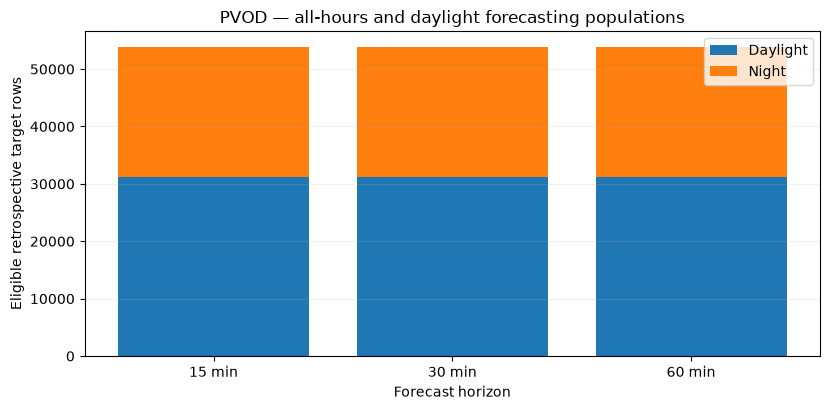

In [6]:
by_horizon = populations.groupby("horizon_min", as_index=False).agg(
    test_all_hours=("sample_test_rows", "sum"),
    test_daylight=("test_daylight_rows", "sum"),
    test_night=("test_night_rows", "sum"),
    refit_rows_across_stations=("refit_rows_label_safe", "sum"),
)
by_horizon["test_daylight_pct"] = (
    100 * by_horizon["test_daylight"] / by_horizon["test_all_hours"]
)
assert (by_horizon["test_daylight"] + by_horizon["test_night"]
        == by_horizon["test_all_hours"]).all()
display(by_horizon)

fig, ax = plt.subplots(figsize=(8.4, 4.2))
positions = np.arange(3)
ax.bar(positions, by_horizon["test_daylight"], label="Daylight")
ax.bar(positions, by_horizon["test_night"],
       bottom=by_horizon["test_daylight"], label="Night")
ax.set_xticks(positions, [f"{h} min" for h in by_horizon["horizon_min"]])
ax.set_xlabel("Forecast horizon")
ax.set_ylabel("Eligible retrospective target rows")
ax.set_title("PVOD — all-hours and daylight forecasting populations")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Save the preparation and protocol audits

The tables below join the previous exploration outputs in `results/pvod_methodology/`. They record each station's chronological boundaries, gap-safe training and test populations, feature-family structure and sampled timestamp-alignment checks. The full PVOD prediction/score files remain in their original evaluation directory.

In [7]:
OUTPUT = PROJECT_ROOT / "results" / "pvod_methodology"
OUTPUT.mkdir(parents=True, exist_ok=True)
tables = {
    "pvod_split_boundaries.csv": boundaries,
    "pvod_forecasting_populations.csv": populations,
    "pvod_feature_schema_audit.csv": schema_audit,
    "pvod_feature_alignment_audit.csv": alignment_audit,
}
for filename, table in tables.items():
    output_file = OUTPUT / filename
    table.to_csv(output_file, index=False)
    assert output_file.is_file() and len(pd.read_csv(output_file)) == len(table)
    print(output_file.relative_to(PROJECT_ROOT))
assert len(populations) == 30 and len(schema_audit) == 50
assert len(alignment_audit) == 10 and len(boundaries) == 10
print("NOTEBOOK 16: PVOD PREPARATION AND PROTOCOL CHECKS PASSED")

results/pvod_methodology/pvod_split_boundaries.csv
results/pvod_methodology/pvod_forecasting_populations.csv
results/pvod_methodology/pvod_feature_schema_audit.csv
results/pvod_methodology/pvod_feature_alignment_audit.csv
NOTEBOOK 16: PVOD PREPARATION AND PROTOCOL CHECKS PASSED


## Findings and methodological interpretation

The PVOD forecasting protocol uses ten station-specific chronological splits, preserves the exact observed time grid, and requires complete issue-time history and intermediate forecast intervals. Nominal-capacity normalization makes station errors interpretable in p.u. without clipping original measurements. Forecast-valid deterministic calendar and astronomical features are constructed from station time and location, with the categorical Panchang block containing 97 fixed-vocabulary indicators.

The archived station refit/test populations and daylight counts are reproduced exactly, establishing consistency with the completed cross-dataset evaluation. We therefore retain the existing all-hours training design, report daylight and all-hours accuracy separately, and interpret the F3–F4 comparison in the broader F0–F4 feature progression.